## 1. Setup

In [39]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
%matplotlib inline

DATA = "hour.csv"
np.random.seed(0)
out = {}                     # collects all key numbers; saved to results.json at the end

## 2. Load data

In [40]:
df = pd.read_csv(DATA, parse_dates=["dteday"])
out["shape"] = list(df.shape)
out["missing_cells"] = int(df.isna().sum().sum())
out["skew"] = round(float(df["cnt"].skew()), 2)
print("shape:", out["shape"])
print("missing cells:", out["missing_cells"])
print("skewness:", out["skew"])
df.head()

shape: [17379, 17]
missing cells: 0
skewness: 1.28


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 3. Exploratory data analysis (Figures 4.1-4.5)

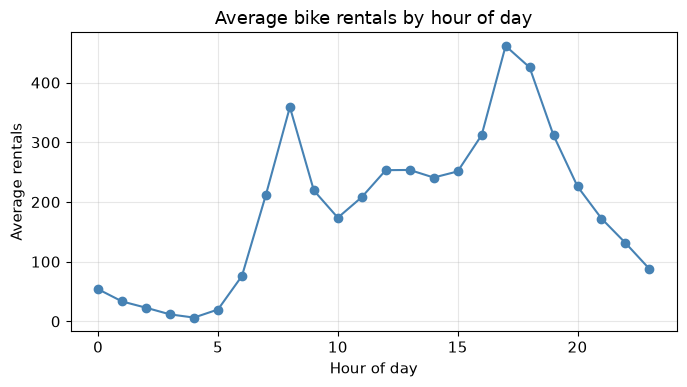

In [41]:
h = df.groupby("hr")["cnt"].mean()
plt.figure(figsize=(7, 4)); plt.plot(h.index, h.values, marker="o", color="steelblue")
plt.xlabel("Hour of day"); plt.ylabel("Average rentals"); plt.title("Average bike rentals by hour of day")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

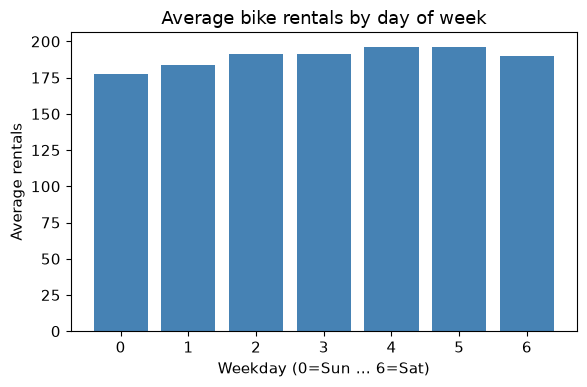

In [42]:
w = df.groupby("weekday")["cnt"].mean()
plt.figure(figsize=(6, 4)); plt.bar(w.index, w.values, color="steelblue")
plt.xlabel("Weekday (0=Sun ... 6=Sat)"); plt.ylabel("Average rentals"); plt.title("Average bike rentals by day of week")
plt.tight_layout(); plt.show()

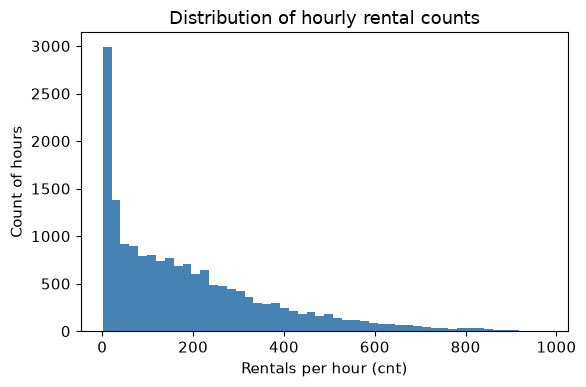

In [43]:
plt.figure(figsize=(6, 4)); plt.hist(df["cnt"], bins=50, color="steelblue")
plt.xlabel("Rentals per hour (cnt)"); plt.ylabel("Count of hours"); plt.title("Distribution of hourly rental counts")
plt.tight_layout(); plt.show()

### Extra EDA: seasonal pattern and rider types

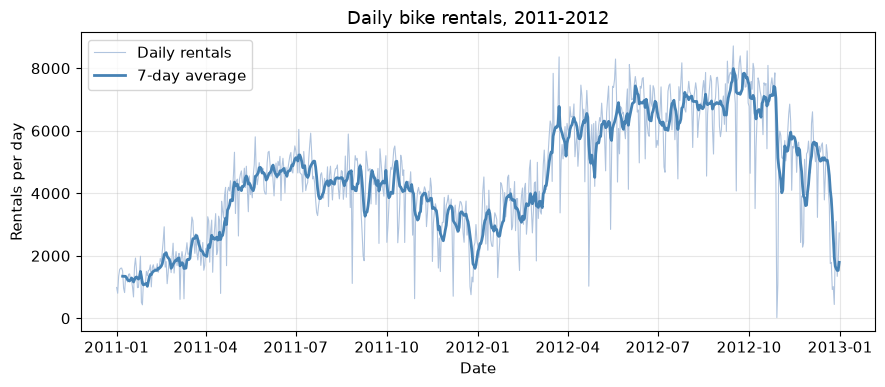

In [44]:
daily = df.groupby("dteday")["cnt"].sum()
plt.figure(figsize=(9, 4))
plt.plot(daily.index, daily.values, color="lightsteelblue", lw=0.8, label="Daily rentals")
plt.plot(daily.index, daily.rolling(7).mean(), color="steelblue", lw=2, label="7-day average")
plt.xlabel("Date"); plt.ylabel("Rentals per day"); plt.title("Daily bike rentals, 2011-2012")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

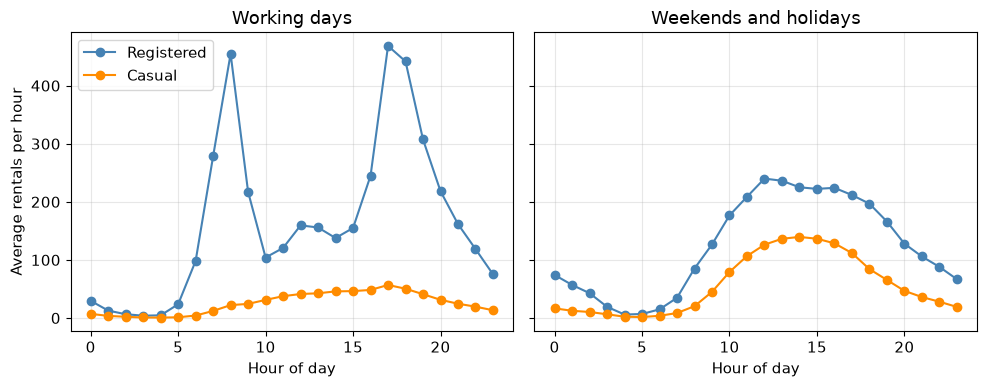

In [45]:
by_type = df.groupby(["workingday", "hr"])[["casual", "registered"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, wd, title in [(axes[0], 1, "Working days"), (axes[1], 0, "Weekends and holidays")]:
    ax.plot(by_type.loc[wd].index, by_type.loc[wd]["registered"], marker="o", color="steelblue", label="Registered")
    ax.plot(by_type.loc[wd].index, by_type.loc[wd]["casual"], marker="o", color="darkorange", label="Casual")
    ax.set_title(title); ax.set_xlabel("Hour of day"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Average rentals per hour"); axes[0].legend()
plt.tight_layout(); plt.show()

## 4. Lag feature (built by timestamp, not by shifting rows)
`lag_168h` = count at the same hour one week earlier. Looked up by timestamp, because sorting by date + `shift(168)` was wrong (hours out of order, 165 missing hours).

In [46]:
df["ts"] = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")
df = df.sort_values("ts").reset_index(drop=True)
assert df["ts"].is_unique

full = pd.date_range(df["ts"].min(), df["ts"].max(), freq="h")
out["expected_hours"] = len(full)
out["missing_hours"] = len(full) - len(df)

# look up the count observed exactly 168 hours earlier
count_at = df.set_index("ts")["cnt"]
df["lag_168h"] = (df["ts"] - pd.Timedelta(hours=168)).map(count_at)
print("expected hours:", out["expected_hours"])
print("missing hours:", out["missing_hours"])

expected hours: 17544
missing hours: 165


Check the lag with a second method (date − 7 days, same hour).

In [47]:
week_before = df[["dteday", "hr", "cnt"]].copy()
week_before["dteday"] = week_before["dteday"] + pd.Timedelta(days=7)
week_before = week_before.rename(columns={"cnt": "cnt_week_before"})
check = df[["dteday", "hr", "lag_168h"]].merge(week_before, on=["dteday", "hr"], how="left")

same = (check["lag_168h"] == check["cnt_week_before"]) | (check["lag_168h"].isna() & check["cnt_week_before"].isna())
assert same.all(), "lag feature does not match the independent check"
print("Lag verified on all", len(check), "rows")

Lag verified on all 17379 rows


In [48]:
# How wrong was the old construction?
# (a) old pipeline exactly as before: sort by date only, then shift 168 rows
old = pd.read_csv(DATA, parse_dates=["dteday"]).sort_values("dteday").reset_index(drop=True)
old["ts"] = old["dteday"] + pd.to_timedelta(old["hr"], unit="h")
old["old_lag"] = old["cnt"].shift(168)
old["true_lag"] = (old["ts"] - pd.Timedelta(hours=168)).map(count_at)
ok = old["old_lag"].notna() & old["true_lag"].notna()
out["old_pipeline_wrong_rows"] = [int((old.loc[ok, "old_lag"] != old.loc[ok, "true_lag"]).sum()), int(ok.sum())]

# (b) even with rows in the right order, a 168-row shift is wrong because of the missing hours
shifted = df["cnt"].shift(168)
ok2 = shifted.notna() & df["lag_168h"].notna()
out["ordered_shift_wrong_rows"] = [int((shifted[ok2] != df.loc[ok2, "lag_168h"]).sum()), int(ok2.sum())]

d = df.dropna(subset=["lag_168h"]).reset_index(drop=True)
out["rows_before_lag"], out["rows_after_lag"] = len(df), len(d)
print("old pipeline wrong rows:", out["old_pipeline_wrong_rows"])
print("ordered 168-row shift wrong rows:", out["ordered_shift_wrong_rows"])
print("rows before lag:", out["rows_before_lag"])
print("rows after lag:", out["rows_after_lag"])

old pipeline wrong rows: [13895, 17068]
ordered 168-row shift wrong rows: [5186, 17068]
rows before lag: 17379
rows after lag: 17075


## 5. Chronological train / validation / test split (70 / 15 / 15)

In [49]:
feats = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit",
         "temp", "atemp", "hum", "windspeed", "lag_168h"]
n = len(d); i1, i2 = int(n * 0.70), int(n * 0.85)
tr, va, te = d.iloc[:i1], d.iloc[i1:i2], d.iloc[i2:]
Xtr, ytr = tr[feats], tr["cnt"]
Xva, yva = va[feats], va["cnt"].values
Xte, yte = te[feats], te["cnt"].values

out["n_train"], out["n_val"], out["n_test"] = len(tr), len(va), len(te)
out["val_period"] = [str(va["ts"].min()), str(va["ts"].max())]
out["test_period"] = [str(te["ts"].min()), str(te["ts"].max())]
print("train rows:", out["n_train"])
print("validation rows:", out["n_val"])
print("test rows:", out["n_test"])
print("validation period:", out["val_period"])
print("test period:", out["test_period"])

train rows: 11952
validation rows: 2561
test rows: 2562
validation period: ['2012-05-29 06:00:00', '2012-09-12 22:00:00']
test period: ['2012-09-12 23:00:00', '2012-12-31 23:00:00']


## 6. Metrics
Cost = r × under-prediction + over-prediction. At r = 1 it equals MAE.

In [50]:
def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - p) ** 2)))

def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y) - p)))

def under_over(y, p):
    """Average under-prediction and average over-prediction (in bikes)."""
    e = np.asarray(y) - np.asarray(p)
    return float(np.maximum(e, 0).mean()), float(np.maximum(-e, 0).mean())

def avg_cost(y, p, r):
    under, over = under_over(y, p)
    return r * under + over

## 7. Arm A: hyperparameter tuning on the validation block only (by RMSE)

In [51]:
rf_grid = [dict(max_depth=md, min_samples_leaf=ml) for md in (None, 20) for ml in (1, 3)]
xg_grid = [dict(n_estimators=ne, max_depth=md, learning_rate=lr)
           for ne in (300, 600) for md in (4, 6) for lr in (0.05, 0.1)]

def tune_rf(X_tr, y_tr, X_va, y_va):
    """Fit one Random Forest per setting; keep the one with the lowest validation RMSE."""
    best = None
    for g in rf_grid:
        m = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1, **g).fit(X_tr, y_tr)
        s = rmse(y_va, np.clip(m.predict(X_va), 0, None))
        if best is None or s < best[0]:
            best = (s, g, m)
    return best[2], best[1]          # fitted model, chosen setting

def tune_xgb(X_tr, y_tr, X_va, y_va):
    """Fit one XGBoost per setting; keep the one with the lowest validation RMSE."""
    best = None
    for g in xg_grid:
        m = XGBRegressor(random_state=0, **g).fit(X_tr, y_tr)
        s = rmse(y_va, np.clip(m.predict(X_va), 0, None))
        if best is None or s < best[0]:
            best = (s, g, m)
    return best[2], best[1]

# these two functions are used again in Section 15 (rolling-origin)
rf, rf_best = tune_rf(Xtr, ytr, Xva, yva)
xg, xg_best = tune_xgb(Xtr, ytr, Xva, yva)
out["rf_best"], out["xgb_best"] = rf_best, xg_best
print("RF best:", rf_best)
print("XGB best:", xg_best)

RF best: {'max_depth': 20, 'min_samples_leaf': 3}
XGB best: {'n_estimators': 600, 'max_depth': 4, 'learning_rate': 0.1}


## 8. Fit final models and predict on validation and test (Table 4.2)

In [52]:
hw = tr.groupby(["hr", "weekday"])["cnt"].mean(); gm = tr["cnt"].mean()
def hw_predict(X):
    return np.array([hw.get((a, b), gm) for a, b in zip(X["hr"], X["weekday"])])

lin = LinearRegression().fit(Xtr, ytr)      # rf and xg were already fitted in Section 7

def predict_all(X):
    preds = {
        "Seasonal Naive":     X["lag_168h"].values.astype(float),
        "Hour x Weekday Avg": hw_predict(X),
        "Linear Regression":  lin.predict(X),
        "Random Forest":      rf.predict(X),
        "XGBoost":            xg.predict(X),
    }
    return {k: np.clip(v, 0, None) for k, v in preds.items()}   # rentals cannot be negative

P  = predict_all(Xte)    # test predictions (used once, for the reported scores)
PV = predict_all(Xva)    # validation predictions (used only for the decision step in Section 13)
names = list(P)

res = pd.DataFrame({k: {"RMSE": rmse(yte, v), "MAE": mae(yte, v)} for k, v in P.items()}).T.round(1)
res.to_csv("results_table.csv")
res

,RMSE,MAE
Seasonal Naive,115.2,67.4
Hour x Weekday Avg,148.6,102.4
Linear Regression,100.2,65.0
Random Forest,89.3,55.7
XGBoost,73.8,47.2


In [53]:
# sanity check: cost at r = 1 must equal MAE for every model
for k, v in P.items():
    assert np.isclose(avg_cost(yte, v, 1), mae(yte, v)), k
out["r1_check"] = "passed"; print("r = 1 check passed")

r = 1 check passed


## 9. Arm A: cost sweep over r = 0.25 to 10 (Table 4.3)

In [54]:
r_fine = np.round(np.arange(0.10, 10.001, 0.01), 2)          # fine grid, used to find where the best model changes
fine = {k: np.array([avg_cost(yte, v, r) for r in r_fine]) for k, v in P.items()}
best_idx = np.vstack([fine[k] for k in names]).argmin(axis=0)

out["best_changes"] = [(float(r_fine[i]), names[best_idx[i - 1]], names[best_idx[i]])
                       for i in range(1, len(r_fine)) if best_idx[i] != best_idx[i - 1]]
print("Best-model switches (r, from, to):", out["best_changes"])

sample_r = [0.25, 0.5, 1, 3, 5, 10]
rank = pd.DataFrame({r: {k: avg_cost(yte, v, r) for k, v in P.items()} for r in sample_r}).round(1)
rank.loc["Best model"] = [rank[r].idxmin() for r in sample_r]
rank

Best-model switches (r, from, to): [(3.87, 'XGBoost', 'Seasonal Naive')]


,0.25,0.50,1.00,3.00,5.00,10.00
Seasonal Naive,47.4,54.1,67.4,120.7,174.0,307.2
Hour x Weekday Avg,36.4,58.4,102.4,278.6,454.8,895.2
Linear Regression,41.5,49.4,65.0,127.8,190.5,347.3
Random Forest,29.0,37.9,55.7,126.8,198.0,375.9
XGBoost,22.0,30.4,47.2,114.6,182.0,350.4
Best model,XGBoost,XGBoost,XGBoost,XGBoost,Seasonal Naive,Seasonal Naive


### Crossover r* between XGBoost and Seasonal Naive
r* = (over_SN − over_XGB) / (under_XGB − under_SN), on test and validation.

In [55]:
def crossover(y, p_xgb, p_naive):
    """Smallest r at which Seasonal Naive becomes cheaper than XGBoost (inf = never)."""
    uX, oX = under_over(y, p_xgb)
    uS, oS = under_over(y, p_naive)
    if uX <= uS:                  # XGBoost does not under-predict more, so Naive never overtakes it as r grows
        return np.inf
    return max((oS - oX) / (uX - uS), 0.0)

out["rstar_test"] = crossover(yte, P["XGBoost"], P["Seasonal Naive"])
out["rstar_validation"] = crossover(yva, PV["XGBoost"], PV["Seasonal Naive"])
out["under_over_test"] = {k: under_over(yte, v) for k, v in P.items()}
out["under_over_val"] = {k: under_over(yva, v) for k, v in PV.items()}
out["mean_actual_vs_lag"] = {"validation": [float(yva.mean()), float(va["lag_168h"].mean())],
                             "test": [float(yte.mean()), float(te["lag_168h"].mean())]}
print("r* on test:", out["rstar_test"])
print("r* on validation:", out["rstar_validation"])
print("mean actual vs mean lag:", out["mean_actual_vs_lag"])

r* on test: 3.865189848852279
r* on validation: inf
mean actual vs mean lag: {'validation': [282.5743850058571, 279.80866848887155], 'test': [235.51170960187355, 249.6639344262295]}


## 10. Figures 4.6-4.8

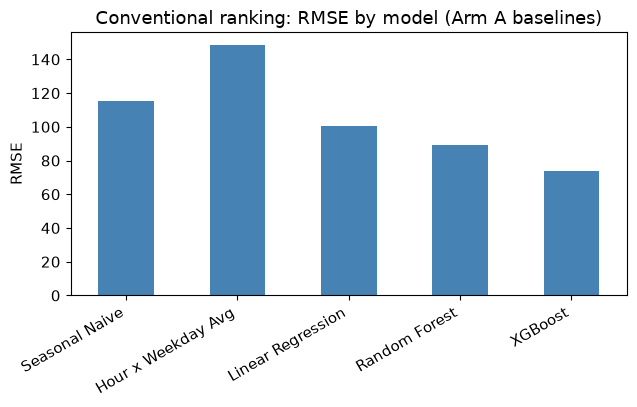

In [56]:
plt.figure(figsize=(6.5, 4.2)); res["RMSE"].plot(kind="bar", color="steelblue")
plt.ylabel("RMSE"); plt.title("Conventional ranking: RMSE by model (Arm A baselines)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

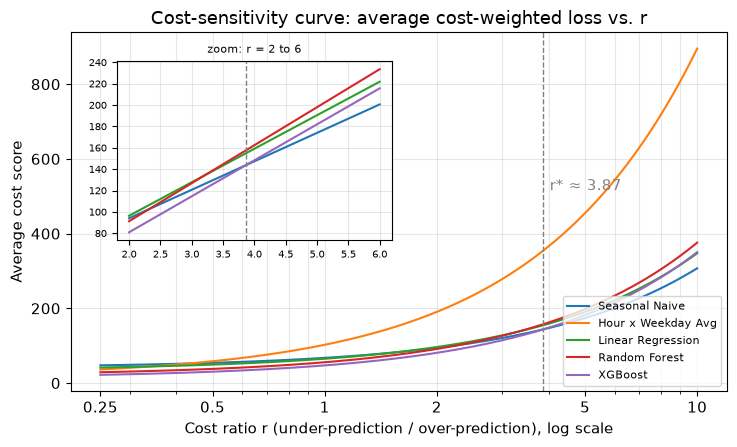

In [57]:
ticks = [0.25, 0.5, 1, 2, 5, 10]
mask = r_fine >= 0.25
plt.figure(figsize=(7.5, 4.6))
lines_ = {k: plt.plot(r_fine[mask], fine[k][mask], label=k)[0] for k in names}
xr = out["rstar_test"]
if 0.25 < xr < 10:
    plt.axvline(xr, color="gray", ls="--", lw=1)
    plt.text(xr * 1.04, plt.ylim()[1] * 0.55, f"r* ≈ {xr:0.2f}", color="gray")
plt.xscale("log"); plt.xticks(ticks, [str(t) for t in ticks])
plt.xlabel("Cost ratio r (under-prediction / over-prediction), log scale"); plt.ylabel("Average cost score")
plt.title("Cost-sensitivity curve: average cost-weighted loss vs. r"); plt.legend(fontsize=8, loc="lower right"); plt.grid(alpha=0.3, which="both")
# zoomed inset around the crossover (Hour x Weekday Avg left out, it is far above the others)
ax_in = plt.gca().inset_axes([0.07, 0.42, 0.42, 0.5])
zoom = (r_fine >= 2) & (r_fine <= 6)
for k in names:
    if k != "Hour x Weekday Avg":
        ax_in.plot(r_fine[zoom], fine[k][zoom], color=lines_[k].get_color())
ax_in.axvline(xr, color="gray", ls="--", lw=1)
ax_in.set_title("zoom: r = 2 to 6", fontsize=8); ax_in.tick_params(labelsize=7); ax_in.grid(alpha=0.3)
plt.tight_layout(); plt.show()

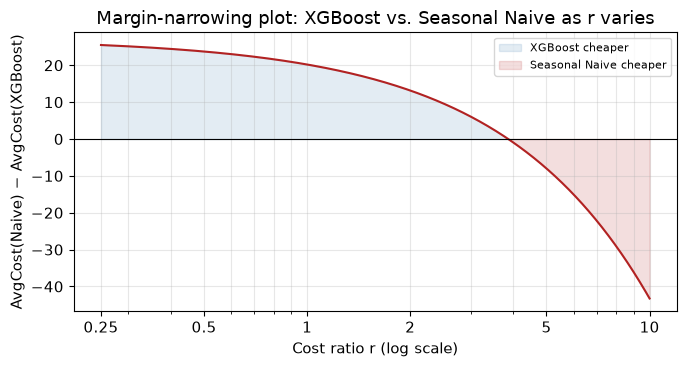

Seasonal Naive minus XGBoost: {'0.25': 25.49226057699974, '0.5': 23.72940290957373, '1': 20.203687574721698, '3': 6.100826235313576, '5': -8.002035104094546, '10': -43.259188452614865}
Random Forest minus XGBoost: {'0.25': 7.037032410870381, '0.5': 7.5103783778268465, '1': 8.457070311739784, '3': 12.24383804739152, '5': 16.030605783043285, '10': 25.49752512217259}


In [58]:
# margin between Seasonal Naive and XGBoost as r varies (positive = XGBoost cheaper)
diff = fine["Seasonal Naive"][mask] - fine["XGBoost"][mask]
rr = r_fine[mask]
plt.figure(figsize=(7, 3.8))
plt.plot(rr, diff, color="firebrick"); plt.axhline(0, color="k", lw=0.8)
plt.fill_between(rr, 0, diff, where=diff > 0, color="steelblue", alpha=0.15, label="XGBoost cheaper")
plt.fill_between(rr, 0, diff, where=diff < 0, color="firebrick", alpha=0.15, label="Seasonal Naive cheaper")
plt.xscale("log"); plt.xticks(ticks, [str(t) for t in ticks])
plt.xlabel("Cost ratio r (log scale)"); plt.ylabel("AvgCost(Naive) − AvgCost(XGBoost)")
plt.title("Margin-narrowing plot: XGBoost vs. Seasonal Naive as r varies"); plt.legend(fontsize=8); plt.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

at = lambda r: int(np.where(r_fine == r)[0][0])
out["margin_naive_minus_xgb"] = {str(r): float(fine["Seasonal Naive"][at(r)] - fine["XGBoost"][at(r)]) for r in sample_r}
out["margin_rf_minus_xgb"] = {str(r): float(fine["Random Forest"][at(r)] - fine["XGBoost"][at(r)]) for r in sample_r}
print("Seasonal Naive minus XGBoost:", out["margin_naive_minus_xgb"])
print("Random Forest minus XGBoost:", out["margin_rf_minus_xgb"])

## 11. Error asymmetry: under- vs. over-prediction (Figure 4.9)

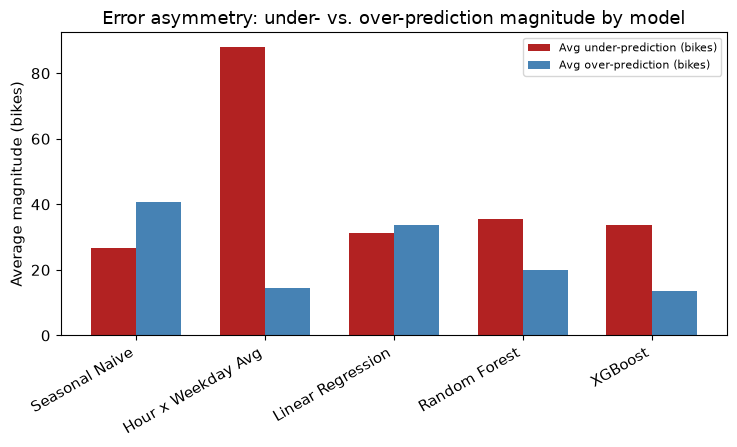

,avg_under,avg_over
Seasonal Naive,26.64,40.79
Hour x Weekday Avg,88.08,14.36
Linear Regression,31.37,33.68
Random Forest,35.58,20.10
XGBoost,33.69,13.53


In [59]:
asym = pd.DataFrame(out["under_over_test"], index=["avg_under", "avg_over"]).T.round(2)
asym.to_csv("asymmetry_table.csv")

x = np.arange(len(asym)); wd = 0.35
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.bar(x - wd / 2, asym["avg_under"], wd, label="Avg under-prediction (bikes)", color="firebrick")
ax.bar(x + wd / 2, asym["avg_over"], wd, label="Avg over-prediction (bikes)", color="steelblue")
ax.set_xticks(x); ax.set_xticklabels(asym.index, rotation=30, ha="right"); ax.set_ylabel("Average magnitude (bikes)")
ax.set_title("Error asymmetry: under- vs. over-prediction magnitude by model"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
asym

## 12. Uncertainty of r*: moving-block bootstrap (1-week blocks, 1,000 resamples)
Models fixed, test hours resampled; r* = inf if Seasonal Naive never overtakes XGBoost.

In [60]:
rng = np.random.default_rng(0)
L = 168                                   # block length = one week of hours
n_blocks = int(np.ceil(len(yte) / L))
stars = []
for _ in range(1000):
    starts = rng.integers(0, len(yte) - L, n_blocks)
    ix = np.concatenate([np.arange(s, s + L) for s in starts])[:len(yte)]
    stars.append(crossover(yte[ix], P["XGBoost"][ix], P["Seasonal Naive"][ix]))
stars = np.array(stars)

out["rstar_boot"] = dict(p2_5=float(np.percentile(stars, 2.5)), median=float(np.median(stars)),
                         p97_5=float(np.percentile(stars, 97.5)),
                         share_le1=float((stars <= 1).mean()), share_gt10=float((stars > 10).mean()),
                         share_never=float(np.isinf(stars).mean()))
out["rstar_boot"]

{'p2_5': 1.831089292257619,
 'median': 3.2765316771224184,
 'p97_5': 30.454256415933656,
 'share_le1': 0.0,
 'share_gt10': 0.071,
 'share_never': 0.017}

## 13. From evaluation to optimization: cost-optimal decisions (Table 4.4)
The cost-optimal plan is the α-quantile of demand, α = r / (1 + r). Three ways: validation shift, hour-of-day shift, Arm B (quantile XGBoost).

In [61]:
def const_shift(y_val, p_val, p_test, r):
    """Move the test forecast by the r/(1+r) quantile of the validation errors (one shift for all hours)."""
    shift = np.quantile(y_val - p_val, r / (1 + r))
    return np.clip(p_test + shift, 0, None)

def hour_shift(y_val, p_val, hr_val, p_test, hr_test, r):
    """Same idea, but a separate shift for each hour of the day (0-23)."""
    alpha = r / (1 + r)
    errors = y_val - p_val
    shift_for_hour = {h: np.quantile(errors[hr_val == h], alpha) for h in range(24)}
    shift = np.array([shift_for_hour[h] for h in hr_test])
    return np.clip(p_test + shift, 0, None)

# short versions for the main split
def shifted(model, r):
    return const_shift(yva, PV[model], P[model], r)

def shifted_by_hour(model, r):
    return hour_shift(yva, PV[model], va["hr"].values, P[model], te["hr"].values, r)

ratios = [0.25, 0.5, 1, 3, 5, 10]
shift_table = pd.DataFrame({r: {k: avg_cost(yte, shifted(k, r), r) for k in names} for r in ratios}).round(1)
shift_table.loc["Best model"] = [shift_table[r].idxmin() for r in ratios]
shift_table.to_csv("shifted_cost_table.csv")
print("Constant shift, all models:")
display(shift_table)

# size of the constant shift for XGBoost (the report quotes the value at r = 5)
out["xgb_constant_shift"] = {str(r): float(np.quantile(yva - PV["XGBoost"], r / (1 + r))) for r in ratios}
print("XGBoost constant shift (bikes):", out["xgb_constant_shift"])

hour_table = pd.DataFrame({r: {k: avg_cost(yte, shifted_by_hour(k, r), r) for k in names} for r in ratios}).round(1)
hour_table.loc["Best model"] = [hour_table[r].idxmin() for r in ratios]
hour_table.to_csv("hour_shift_cost_table.csv")
out["hour_shift_best"] = {str(r): hour_table.loc["Best model", r] for r in ratios}
print("Hour-of-day shift, all models:")
display(hour_table)

Constant shift, all models:


,0.25,0.50,1.00,3.00,5.00,10.00
Seasonal Naive,38.3,51.5,67.6,115.0,148.7,205.8
Hour x Weekday Avg,38.4,65.1,102.7,184.6,230.0,286.3
Linear Regression,28.5,43.4,65.5,119.6,153.4,205.9
Random Forest,24.7,37.3,55.6,107.5,140.2,189.2
XGBoost,20.7,30.9,46.6,90.1,115.1,151.1
Best model,XGBoost,XGBoost,XGBoost,XGBoost,XGBoost,XGBoost


XGBoost constant shift (bikes): {'0.25': -40.921295166015625, '0.5': -13.392237345377607, '1': 2.632598876953125, '3': 35.29150390625, '5': 64.0884755452474, '10': 103.80325594815339}
Hour-of-day shift, all models:


,0.25,0.50,1.00,3.00,5.00,10.00
Seasonal Naive,35.3,49.4,67.6,110.5,137.4,181.1
Hour x Weekday Avg,49.6,68.2,91.8,130.7,151.7,178.2
Linear Regression,28.4,42.7,62.5,106.8,130.0,163.1
Random Forest,24.8,37.5,54.2,88.7,108.0,136.8
XGBoost,21.8,33.4,48.0,77.7,93.3,113.6
Best model,XGBoost,XGBoost,XGBoost,XGBoost,XGBoost,XGBoost


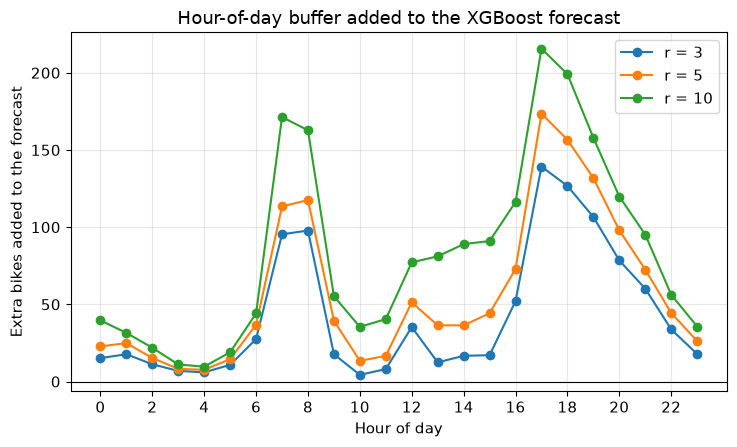

,target,raw forecast,constant shift,hour-of-day shift
1,50.0,37.0,41.0,41.0
3,75.0,37.0,70.0,67.0
5,83.0,37.0,81.0,77.0
10,91.0,37.0,90.0,88.0


In [62]:
# hourly buffer and coverage (Figure 4.10)
alpha_of = lambda r: r / (1 + r)
errors_val = yva - PV["XGBoost"]
plt.figure(figsize=(7.5, 4.6))
buffers = {}
for r in (3, 5, 10):
    buffers[r] = [np.quantile(errors_val[va["hr"].values == h], alpha_of(r)) for h in range(24)]
    plt.plot(range(24), buffers[r], marker="o", label=f"r = {r}")
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("Hour of day"); plt.ylabel("Extra bikes added to the forecast")
plt.title("Hour-of-day buffer added to the XGBoost forecast"); plt.legend(); plt.grid(alpha=0.3)
plt.xticks(range(0, 24, 2)); plt.tight_layout(); plt.show()
out["buffer_r5"] = {h: round(float(b), 1) for h, b in enumerate(buffers[5])}

# coverage = share of test hours in which the plan was at least as high as actual demand
coverage = {}
for r in (1, 3, 5, 10):
    coverage[r] = {"target": alpha_of(r),
                   "raw forecast": float(np.mean(yte <= P["XGBoost"])),
                   "constant shift": float(np.mean(yte <= shifted("XGBoost", r))),
                   "hour-of-day shift": float(np.mean(yte <= shifted_by_hour("XGBoost", r)))}
out["coverage"] = {str(k): v for k, v in coverage.items()}
(100 * pd.DataFrame(coverage).T).round(0)

In [ ]:
# Arm B: up to 3,000 trees, early stopping (~2 min)
armb_grid = [dict(max_depth=md, learning_rate=lr, min_child_weight=mcw)
             for md in (4, 6) for lr in (0.05, 0.1) for mcw in (1, 10)]
armb = {}
for r in [0.5, 1, 3, 5, 10]:
    alpha = r / (1 + r)
    best = None
    for g in armb_grid:
        m = XGBRegressor(objective="reg:quantileerror", quantile_alpha=alpha, random_state=0,
                         n_estimators=3000, early_stopping_rounds=100, eval_metric="quantile", **g)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
        s = avg_cost(yva, np.clip(m.predict(Xva), 0, None), r)
        if best is None or s < best[0]:
            best = (s, g, m)
    pb = np.clip(best[2].predict(Xte), 0, None)
    a_costs = {k: avg_cost(yte, v, r) for k, v in P.items()}
    armb[r] = {"alpha": round(alpha, 2),
               "Arm A best model": min(a_costs, key=a_costs.get),
               "Arm A best cost": min(a_costs.values()),
               "Arm A XGBoost": a_costs["XGBoost"],
               "XGBoost + val. shift": avg_cost(yte, shifted("XGBoost", r), r),
               "XGBoost + hour-of-day shift": avg_cost(yte, shifted_by_hour("XGBoost", r), r),
               "Arm B XGBoost": avg_cost(yte, pb, r),
               "Arm B under": under_over(yte, pb)[0], "Arm B over": under_over(yte, pb)[1],
               "Arm B grid": best[1], "Arm B trees": best[2].best_iteration + 1}
table43 = pd.DataFrame(armb).T
out["table_4_3"] = {str(k): v for k, v in armb.items()}
table43.round(1)

In [ ]:
# refitted baseline (train + validation)
trva = pd.concat([tr, va])
xg_refit = XGBRegressor(random_state=0, **xg_best).fit(trva[feats], trva["cnt"])
p_refit = np.clip(xg_refit.predict(Xte), 0, None)
out["main_refit"] = {str(r): {"XGBoost (train only)": avg_cost(yte, P["XGBoost"], r),
                              "XGBoost refitted on train + val": avg_cost(yte, p_refit, r),
                              "XGBoost (train only) + hour-of-day shift": avg_cost(yte, shifted_by_hour("XGBoost", r), r)}
                     for r in (1, 3, 5, 10)}
pd.DataFrame(out["main_refit"]).T.round(1)

,XGBoost (train only),XGBoost refitted on train + val,XGBoost (train only) + hour-of-day shift
1,47.2,42.3,48.0
3,114.6,83.9,77.7
5,182.0,125.6,93.3
10,350.4,229.7,113.6


## 14. High-demand hours (H3)
Peaks = weekday 07, 08, 17, 18 h (defined in advance). Top-10% by actual demand shown only for comparison (biased).

In [ ]:
peak = (te["workingday"].values == 1) & np.isin(te["hr"].values, [7, 8, 17, 18])   # known in advance
top10 = yte >= np.quantile(yte, 0.9)                                                # biased, comparison only
r = 5
methods = [("XGBoost (re-scored)", P["XGBoost"]),
           ("Seasonal Naive (re-scored)", P["Seasonal Naive"]),
           ("XGBoost + constant shift", shifted("XGBoost", r)),
           ("XGBoost + hour-of-day shift", shifted_by_hour("XGBoost", r))]

def peak_stats(mask):
    rows = {}
    for name, p in methods:
        under, over = under_over(yte[mask], p[mask])
        cost = r * np.maximum(yte - p, 0) + np.maximum(p - yte, 0)      # cost of every test hour
        rows[name] = {"peak hours under-predicted (%)": 100 * (yte[mask] > p[mask]).mean(),
                      "avg under in peak hours": under,
                      "avg over in peak hours": over,
                      "share of total cost from peak hours (%)": 100 * cost[mask].sum() / cost.sum()}
    return rows

out["h3_n_peak_hours"] = int(peak.sum())
out["h3_share_of_test_hours"] = float(peak.mean())
out["h3"] = peak_stats(peak)
out["h3_top10_biased"] = peak_stats(top10)
print("calendar peak hours:", out["h3_n_peak_hours"], "of", len(yte))
print("Commute peaks (used in the report):")
display(pd.DataFrame(out["h3"]).T.round(1))
print("Top 10% by actual demand (biased, comparison only):")
display(pd.DataFrame(out["h3_top10_biased"]).T.round(1))

calendar peak hours: 284 of 2562
Commute peaks (used in the report):


,peak hours under-predicted (%),avg under in peak hours,avg over in peak hours,share of total cost from peak hours (%)
XGBoost (re-scored),79.2,101.1,21.6,32.1
Seasonal Naive (re-scored),42.6,58.9,80.8,23.9
XGBoost + constant shift,61.6,56.1,40.7,30.9
XGBoost + hour-of-day shift,33.8,19.5,80.7,21.2


Top 10% by actual demand (biased, comparison only):


,peak hours under-predicted (%),avg under in peak hours,avg over in peak hours,share of total cost from peak hours (%)
XGBoost (re-scored),96.9,122.5,0.8,33.9
Seasonal Naive (re-scored),58.5,75.0,28.1,23.3
XGBoost + constant shift,75.6,66.6,9.0,29.9
XGBoost + hour-of-day shift,55.0,34.9,28.9,22.0


## 15. Rolling-origin evaluation (five two-month test windows)
Compare standard (lowest val. RMSE), re-ranked (lowest val. cost) and standard + hour shift, plus a refitted baseline.

In [ ]:
windows = [("2012-03-01", "2012-05-01"), ("2012-05-01", "2012-07-01"), ("2012-07-01", "2012-09-01"),
           ("2012-09-01", "2012-11-01"), ("2012-11-01", "2013-01-01")]

def fit_window(tr_w, va_w, settings=None):
    """Fit all five models on tr_w and return (predict function, chosen settings).
    Without settings, RF and XGBoost are tuned on va_w (as in Section 7); with settings, those are reused,
    which is how the models are refitted on training + validation data."""
    Xt, yt = tr_w[feats], tr_w["cnt"]
    if settings is None:
        rf_w, rf_set = tune_rf(Xt, yt, va_w[feats], va_w["cnt"])
        xg_w, xg_set = tune_xgb(Xt, yt, va_w[feats], va_w["cnt"])
    else:
        rf_set, xg_set = settings
        rf_w = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1, **rf_set).fit(Xt, yt)
        xg_w = XGBRegressor(random_state=0, **xg_set).fit(Xt, yt)
    hw_w = tr_w.groupby(["hr", "weekday"])["cnt"].mean(); gm_w = yt.mean()
    lin_w = LinearRegression().fit(Xt, yt)
    def predict(X):
        p = {"Seasonal Naive":     X["lag_168h"].values.astype(float),
             "Hour x Weekday Avg": np.array([hw_w.get((a, b), gm_w) for a, b in zip(X["hr"], X["weekday"])]),
             "Linear Regression":  lin_w.predict(X[feats]),
             "Random Forest":      rf_w.predict(X[feats]),
             "XGBoost":            xg_w.predict(X[feats])}
        return {k: np.clip(v, 0, None) for k, v in p.items()}
    return predict, (rf_set, xg_set)

rows = []
for start, end in windows:
    t0 = pd.Timestamp(start); v0 = t0 - pd.DateOffset(months=2)
    tr_w = d[d["ts"] < v0]
    va_w = d[(d["ts"] >= v0) & (d["ts"] < t0)]
    te_w = d[(d["ts"] >= t0) & (d["ts"] < pd.Timestamp(end))]
    predict, settings = fit_window(tr_w, va_w)
    pv, pt = predict(va_w), predict(te_w)
    # fairer baseline: the same models refitted on training + validation data
    predict_refit, _ = fit_window(pd.concat([tr_w, va_w]), None, settings)
    pt_refit = predict_refit(te_w)
    yv, yt = va_w["cnt"].values, te_w["cnt"].values

    standard = min(names, key=lambda k: rmse(yv, pv[k]))           # what standard practice would choose
    for r in (1, 3, 5, 10):
        reranked = min(names, key=lambda k: avg_cost(yv, pv[k], r))
        rows.append({"window": start[:7], "r": r,
                     "r* (XGB vs Naive)": crossover(yt, pt["XGBoost"], pt["Seasonal Naive"]),
                     "standard model": standard,
                     "standard cost": avg_cost(yt, pt[standard], r),
                     "standard refitted (train + val)": avg_cost(yt, pt_refit[standard], r),
                     "re-ranked model": reranked,
                     "re-ranked cost": avg_cost(yt, pt[reranked], r),
                     "standard + constant shift": avg_cost(yt, const_shift(yv, pv[standard], pt[standard], r), r),
                     "standard + hour shift": avg_cost(yt, hour_shift(yv, pv[standard], va_w["hr"].values,
                                                                      pt[standard], te_w["hr"].values, r), r)})
    print("done", start)

roll = pd.DataFrame(rows)
roll["hour shift vs standard (%)"] = 100 * (roll["standard + hour shift"] / roll["standard cost"] - 1)
roll["re-ranked vs standard (%)"] = 100 * (roll["re-ranked cost"] / roll["standard cost"] - 1)
roll["hour shift vs refitted (%)"] = 100 * (roll["standard + hour shift"] / roll["standard refitted (train + val)"] - 1)
roll.to_csv("rolling_origin_table.csv", index=False)
out["rolling_origin"] = roll.round(2).to_dict(orient="records")
roll.round(1)

done 2012-03-01
done 2012-05-01
done 2012-07-01
done 2012-09-01
done 2012-11-01


,window,r,r* (XGB vs Naive),standard model,standard cost,standard refitted (train + val),re-ranked model,re-ranked cost,standard + constant shift,standard + hour shift,hour shift vs standard (%),re-ranked vs standard (%),hour shift vs refitted (%)
0,2012-03,1,0.9,Hour x Weekday Avg,98.2,98.4,Hour x Weekday Avg,98.2,100.2,96.9,-1.3,0.0,-1.5
1,2012-03,3,0.9,Hour x Weekday Avg,284.0,285.2,Hour x Weekday Avg,284.0,249.7,215.9,-24.0,0.0,-24.3
2,2012-03,5,0.9,Hour x Weekday Avg,469.8,472.0,Hour x Weekday Avg,469.8,359.8,318.6,-32.2,0.0,-32.5
3,2012-03,10,0.9,Hour x Weekday Avg,934.3,939.1,Hour x Weekday Avg,934.3,574.3,537.6,-42.5,0.0,-42.8
4,2012-05,1,0.6,XGBoost,66.8,49.1,XGBoost,66.8,66.1,53.7,-19.6,0.0,9.3
5,2012-05,3,0.6,XGBoost,178.4,79.4,Linear Regression,129.2,140.0,95.2,-46.6,-27.6,20.0
6,2012-05,5,0.6,XGBoost,290.0,109.6,Linear Regression,195.2,180.9,118.8,-59.0,-32.7,8.4
7,2012-05,10,0.6,XGBoost,569.1,185.1,Linear Regression,360.2,234.5,147.9,-74.0,-36.7,-20.1
8,2012-07,1,0.5,XGBoost,58.7,45.8,XGBoost,58.7,59.5,58.7,0.1,0.0,28.1
9,2012-07,3,0.5,XGBoost,135.5,115.7,XGBoost,135.5,115.1,98.9,-27.0,0.0,-14.5


In [ ]:
# summary at r = 5 (Table 4.5)
roll[roll["r"] == 5][["window", "r* (XGB vs Naive)", "standard model", "standard cost", "standard refitted (train + val)",
                      "re-ranked model", "re-ranked cost", "standard + constant shift", "standard + hour shift",
                      "hour shift vs standard (%)", "hour shift vs refitted (%)"]].round(1)

,window,r* (XGB vs Naive),standard model,standard cost,standard refitted (train + val),re-ranked model,re-ranked cost,standard + constant shift,standard + hour shift,hour shift vs standard (%),hour shift vs refitted (%)
2,2012-03,0.9,Hour x Weekday Avg,469.8,472.0,Hour x Weekday Avg,469.8,359.8,318.6,-32.2,-32.5
6,2012-05,0.6,XGBoost,290.0,109.6,Linear Regression,195.2,180.9,118.8,-59.0,8.4
10,2012-07,0.5,XGBoost,212.3,185.6,XGBoost,212.3,146.8,122.3,-42.4,-34.1
14,2012-09,4.0,XGBoost,192.2,175.4,Seasonal Naive,187.0,120.4,89.5,-53.4,-49.0
18,2012-11,inf,XGBoost,146.8,129.4,XGBoost,146.8,105.5,88.5,-39.8,-31.7


## 16. Rolling windows: Arm B and a smoothed hourly buffer
XGBoost, hourly buffer, smoothed buffer (hours h−1, h, h+1) and Arm B at r = 3, 5, 10. Takes about 3 min.

In [ ]:
def hour_shift_smooth(y_val, p_val, hr_val, p_test, hr_test, r):
    """Like hour_shift(), but the buffer for hour h uses the errors of hours h-1, h and h+1."""
    alpha = r / (1 + r)
    errors = y_val - p_val
    shift_for_hour = {}
    for h in range(24):
        near = np.isin(hr_val, [(h - 1) % 24, h, (h + 1) % 24])
        shift_for_hour[h] = np.quantile(errors[near], alpha)
    shift = np.array([shift_for_hour[h] for h in hr_test])
    return np.clip(p_test + shift, 0, None)

def coverage(y, plan):
    """Share of hours in which the plan was at least as high as actual demand."""
    return float(np.mean(np.asarray(y) <= plan))

armb_window_grid = [dict(max_depth=4, learning_rate=0.1, min_child_weight=mcw) for mcw in (1, 10)]
rows16 = []
for start, end in windows:
    t0 = pd.Timestamp(start); v0 = t0 - pd.DateOffset(months=2)
    tr_w = d[d["ts"] < v0]
    va_w = d[(d["ts"] >= v0) & (d["ts"] < t0)]
    te_w = d[(d["ts"] >= t0) & (d["ts"] < pd.Timestamp(end))]
    yv, yt = va_w["cnt"].values, te_w["cnt"].values
    hv, ht = va_w["hr"].values, te_w["hr"].values
    xg_w, _ = tune_xgb(tr_w[feats], tr_w["cnt"], va_w[feats], yv)          # same tuning as Section 7
    pv = np.clip(xg_w.predict(va_w[feats]), 0, None)
    pt = np.clip(xg_w.predict(te_w[feats]), 0, None)
    for r in (3, 5, 10):
        best = None
        for g in armb_window_grid:
            m = XGBRegressor(objective="reg:quantileerror", quantile_alpha=r / (1 + r), random_state=0,
                             n_estimators=3000, early_stopping_rounds=100, eval_metric="quantile", **g)
            m.fit(tr_w[feats], tr_w["cnt"], eval_set=[(va_w[feats], yv)], verbose=False)
            s = avg_cost(yv, np.clip(m.predict(va_w[feats]), 0, None), r)
            if best is None or s < best[0]:
                best = (s, m)
        p_armb = np.clip(best[1].predict(te_w[feats]), 0, None)
        p_hour = hour_shift(yv, pv, hv, pt, ht, r)
        p_smooth = hour_shift_smooth(yv, pv, hv, pt, ht, r)
        rows16.append({"window": start[:7], "r": r,
                       "XGBoost re-scored": avg_cost(yt, pt, r),
                       "hourly buffer": avg_cost(yt, p_hour, r),
                       "smoothed hourly buffer": avg_cost(yt, p_smooth, r),
                       "Arm B": avg_cost(yt, p_armb, r),
                       "coverage target": r / (1 + r),
                       "coverage hourly": coverage(yt, p_hour),
                       "coverage smoothed": coverage(yt, p_smooth),
                       "coverage Arm B": coverage(yt, p_armb)})
    print("done", start)
t16 = pd.DataFrame(rows16)
t16.to_csv("rolling_armb_table.csv", index=False)
out["rolling_armb"] = t16.round(3).to_dict(orient="records")
t16.round(2)

done 2012-03-01
done 2012-05-01
done 2012-07-01
done 2012-09-01
done 2012-11-01


,window,r,XGBoost re-scored,hourly buffer,smoothed hourly buffer,Arm B,coverage target,coverage hourly,coverage smoothed,coverage Arm B
0,2012-03,3,195.15,101.59,106.71,130.09,0.75,0.65,0.67,0.56
1,2012-03,5,321.36,131.83,142.41,184.61,0.83,0.73,0.75,0.67
2,2012-03,10,636.88,190.90,203.33,283.90,0.91,0.79,0.81,0.77
3,2012-05,3,178.41,95.21,104.02,125.15,0.75,0.67,0.68,0.64
4,2012-05,5,290.04,118.78,131.49,163.29,0.83,0.75,0.76,0.70
5,2012-05,10,569.10,147.88,154.81,248.30,0.91,0.83,0.86,0.75
6,2012-07,3,135.48,98.92,98.60,90.85,0.75,0.52,0.52,0.73
7,2012-07,5,212.29,122.30,119.98,117.29,0.83,0.63,0.64,0.81
8,2012-07,10,404.33,157.97,157.38,135.86,0.91,0.73,0.76,0.87
9,2012-09,3,120.09,72.10,74.62,101.72,0.75,0.72,0.72,0.64


## 17. Rolling windows with a four-month validation block

In [ ]:
rows17 = []
for start, end in windows:
    t0 = pd.Timestamp(start); v4 = t0 - pd.DateOffset(months=4)
    tr4 = d[d["ts"] < v4]
    va4 = d[(d["ts"] >= v4) & (d["ts"] < t0)]
    te_w = d[(d["ts"] >= t0) & (d["ts"] < pd.Timestamp(end))]
    yv4, yt = va4["cnt"].values, te_w["cnt"].values
    xg4, _ = tune_xgb(tr4[feats], tr4["cnt"], va4[feats], yv4)
    pv4 = np.clip(xg4.predict(va4[feats]), 0, None)
    pt4 = np.clip(xg4.predict(te_w[feats]), 0, None)
    for r in (3, 5, 10):
        p = hour_shift_smooth(yv4, pv4, va4["hr"].values, pt4, te_w["hr"].values, r)
        rows17.append({"window": start[:7], "r": r,
                       "smoothed hourly buffer, 4-month validation": avg_cost(yt, p, r),
                       "coverage": coverage(yt, p)})
t17 = pd.DataFrame(rows17)
compare = t16[["window", "r", "smoothed hourly buffer", "coverage smoothed"]].merge(t17, on=["window", "r"])
compare.to_csv("validation_length_table.csv", index=False)
out["validation_length"] = compare.round(3).to_dict(orient="records")
compare.round(2)

,window,r,smoothed hourly buffer,coverage smoothed,"smoothed hourly buffer, 4-month validation",coverage
0,2012-03,3,106.71,0.67,124.83,0.52
1,2012-03,5,142.41,0.75,168.14,0.62
2,2012-03,10,203.33,0.81,239.83,0.74
3,2012-05,3,104.02,0.68,109.98,0.70
4,2012-05,5,131.49,0.76,141.26,0.78
5,2012-05,10,154.81,0.86,180.62,0.84
6,2012-07,3,98.60,0.52,104.51,0.64
7,2012-07,5,119.98,0.64,129.00,0.74
8,2012-07,10,157.38,0.76,159.42,0.87
9,2012-09,3,74.62,0.72,96.34,0.56


## 18. Random seeds (main split)
Five seeds with subsample = 0.8 (default XGBoost ignores the seed).

In [ ]:
seed_rows = []
for seed in range(5):
    xs = XGBRegressor(random_state=seed, subsample=0.8, **xg_best).fit(Xtr, ytr)
    pvs = np.clip(xs.predict(Xva), 0, None)
    pts = np.clip(xs.predict(Xte), 0, None)
    mb = XGBRegressor(objective="reg:quantileerror", quantile_alpha=5 / 6, random_state=seed, subsample=0.8,
                      n_estimators=3000, early_stopping_rounds=100, eval_metric="quantile", **armb[5]["Arm B grid"])
    mb.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    seed_rows.append({"seed": seed,
                      "RMSE": rmse(yte, pts),
                      "r* (XGB vs Naive)": crossover(yte, pts, P["Seasonal Naive"]),
                      "XGBoost re-scored, r=5": avg_cost(yte, pts, 5),
                      "XGBoost + hourly buffer, r=5": avg_cost(yte, hour_shift(yva, pvs, va["hr"].values, pts, te["hr"].values, 5), 5),
                      "Arm B, r=5": avg_cost(yte, np.clip(mb.predict(Xte), 0, None), 5)})
t18 = pd.DataFrame(seed_rows)
out["seeds"] = t18.round(3).to_dict(orient="records")
summary18 = t18.drop(columns="seed").agg(["min", "mean", "max"]).round(2)
out["seeds_summary"] = summary18.to_dict()
display(t18.round(2)); summary18

,seed,RMSE,r* (XGB vs Naive),"XGBoost re-scored, r=5","XGBoost + hourly buffer, r=5","Arm B, r=5"
0,0,74.21,3.65,184.12,90.57,121.84
1,1,73.89,3.50,185.81,89.88,122.72
2,2,73.68,3.72,183.22,93.33,124.06
3,3,73.08,3.83,182.53,91.42,121.71
4,4,73.58,3.89,181.50,93.65,125.56


,RMSE,r* (XGB vs Naive),"XGBoost re-scored, r=5","XGBoost + hourly buffer, r=5","Arm B, r=5"
min,73.08,3.50,181.50,89.88,121.71
mean,73.69,3.72,183.44,91.77,123.18
max,74.21,3.89,185.81,93.65,125.56


## 19. Seoul replication (second city)
Closed hours dropped; same lag and split. Features differ from Washington (no working-day flag; extra weather columns; weekday 0 = Monday).

In [ ]:
s = pd.read_csv("SeoulBikeData.csv", encoding="latin1")
s.columns = ["date", "cnt", "hr", "temp", "hum", "wind", "vis", "dew", "solar", "rain", "snow",
             "season", "holiday", "functioning"]
s["ts"] = pd.to_datetime(s["date"], dayfirst=True) + pd.to_timedelta(s["hr"], unit="h")
s = s.sort_values("ts").reset_index(drop=True)
s["weekday"] = s["ts"].dt.dayofweek
s["mnth"] = s["ts"].dt.month
s["season"] = s["season"].map({"Winter": 0, "Spring": 1, "Summer": 2, "Autumn": 3})
s["holiday"] = (s["holiday"] == "Holiday").astype(int)

open_hours = s[s["functioning"] == "Yes"]
count_at_s = open_hours.set_index("ts")["cnt"]
s["lag_168h"] = (s["ts"] - pd.Timedelta(hours=168)).map(count_at_s)    # missing if that hour was closed
sd = s[(s["functioning"] == "Yes") & s["lag_168h"].notna()].reset_index(drop=True)

feats_s = ["hr", "temp", "hum", "wind", "vis", "dew", "solar", "rain", "snow",
           "season", "holiday", "weekday", "mnth", "lag_168h"]
n_s = len(sd); j1, j2 = int(n_s * 0.70), int(n_s * 0.85)
tr_s, va_s, te_s = sd.iloc[:j1], sd.iloc[j1:j2], sd.iloc[j2:]
yv_s, yt_s = va_s["cnt"].values, te_s["cnt"].values

xg_s, xg_s_best = tune_xgb(tr_s[feats_s], tr_s["cnt"], va_s[feats_s], yv_s)
pv_s = {"Seasonal Naive": va_s["lag_168h"].values.astype(float), "XGBoost": np.clip(xg_s.predict(va_s[feats_s]), 0, None)}
pt_s = {"Seasonal Naive": te_s["lag_168h"].values.astype(float), "XGBoost": np.clip(xg_s.predict(te_s[feats_s]), 0, None)}

seoul = {"rows used": n_s, "rows dropped (closed hours or no lag)": len(s) - n_s,
         "test period": [str(te_s["ts"].min()), str(te_s["ts"].max())], "xgb_best": xg_s_best,
         "r* (XGB vs Naive)": crossover(yt_s, pt_s["XGBoost"], pt_s["Seasonal Naive"])}
rows19 = []
for k in pt_s:
    row = {"model": k, "RMSE": rmse(yt_s, pt_s[k]), "MAE": mae(yt_s, pt_s[k])}
    for r in (0.5, 1, 3, 5, 10):
        row[f"re-scored r={r}"] = avg_cost(yt_s, pt_s[k], r)
        row[f"hourly buffer r={r}"] = avg_cost(yt_s, hour_shift(yv_s, pv_s[k], va_s["hr"].values, pt_s[k], te_s["hr"].values, r), r)
    row["coverage hourly buffer r=5"] = coverage(yt_s, hour_shift(yv_s, pv_s[k], va_s["hr"].values, pt_s[k], te_s["hr"].values, 5))
    rows19.append(row)
t19 = pd.DataFrame(rows19).set_index("model")
seoul["table"] = t19.round(2).to_dict(orient="index")
out["seoul"] = seoul
print("rows used:", seoul["rows used"])
print("rows dropped:", seoul["rows dropped (closed hours or no lag)"])
print("test period:", seoul["test period"])
print("XGBoost settings:", seoul["xgb_best"])
print("r* (XGB vs Naive):", seoul["r* (XGB vs Naive)"])
t19.round(1).T

rows used: 8026
rows dropped: 734
test period: ['2018-09-24 06:00:00', '2018-11-30 23:00:00']
XGBoost settings: {'n_estimators': 600, 'max_depth': 6, 'learning_rate': 0.05}
r* (XGB vs Naive): inf


model,Seasonal Naive,XGBoost
RMSE,442.2,241.8
MAE,267.1,158.5
re-scored r=0.5,210.4,106.6
hourly buffer r=0.5,197.2,113.4
re-scored r=1,267.1,158.5
hourly buffer r=1,286.5,160.6
re-scored r=3,494.0,366.4
hourly buffer r=3,506.7,251.7
re-scored r=5,720.9,574.2
hourly buffer r=5,664.5,305.7


## 20. Fair comparisons and uncertainty of the gains
Arm B and the plain model also get the validation data (refitted), refit + buffer is tested, and the gains get bootstrap intervals. r = 2 is added to check the gap between r = 1 and r = 3.

In [ ]:
# main split: same Arm B as Section 13, plus versions refitted on train + validation
hv, ht = va["hr"].values, te["hr"].values
armb_pred, armb_refit_pred, rows20 = {}, {}, []
for r in (1, 2, 3, 5, 10):
    alpha = r / (1 + r)
    if r in armb:                      # same Arm B as Section 13
        g = armb[r]["Arm B grid"]
    else:                              # r = 2 is not in Section 13: tune it the same way
        g = min(armb_grid, key=lambda gg: avg_cost(yva, np.clip(XGBRegressor(
            objective="reg:quantileerror", quantile_alpha=alpha, random_state=0, n_estimators=3000,
            early_stopping_rounds=100, eval_metric="quantile", **gg).fit(Xtr, ytr, eval_set=[(Xva, yva)],
            verbose=False).predict(Xva), 0, None), r))
    mb = XGBRegressor(objective="reg:quantileerror", quantile_alpha=alpha, random_state=0,
                      n_estimators=3000, early_stopping_rounds=100, eval_metric="quantile", **g)
    mb.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    mbr = XGBRegressor(objective="reg:quantileerror", quantile_alpha=alpha, random_state=0,
                       n_estimators=mb.best_iteration + 1, **g).fit(trva[feats], trva["cnt"])
    armb_pred[r] = np.clip(mb.predict(Xte), 0, None)
    armb_refit_pred[r] = np.clip(mbr.predict(Xte), 0, None)
    plans = {"XGBoost": P["XGBoost"],
             "XGBoost refitted": p_refit,
             "XGBoost + hourly buffer": shifted_by_hour("XGBoost", r),
             "refitted XGBoost + hourly buffer": hour_shift(yva, PV["XGBoost"], hv, p_refit, ht, r),
             "Arm B": armb_pred[r],
             "Arm B refitted": armb_refit_pred[r]}
    for k, p in plans.items():
        rows20.append({"r": r, "plan": k, "cost": avg_cost(yte, p, r), "coverage": coverage(yte, p)})
t20 = pd.DataFrame(rows20)
assert abs(t20.query("r == 5 and plan == 'Arm B'")["cost"].item() - armb[5]["Arm B XGBoost"]) < 1e-6  # same as Section 13
out["fair_main"] = t20.round(3).to_dict(orient="records")
n_per_hour = va.groupby("hr").size()
print("validation errors per hour (main split):", n_per_hour.min(), "to", n_per_hour.max())
display(t20.pivot(index="plan", columns="r", values="cost").round(1))
t20.pivot(index="plan", columns="r", values="coverage").round(2)

validation errors per hour (main split): 106 to 107


r,1,2,3,5,10
plan,,,,,
Arm B,49.2,76.8,96.5,123.6,161.5
Arm B refitted,45.2,64.6,76.7,104.6,141.7
XGBoost,47.2,80.9,114.6,182.0,350.4
XGBoost + hourly buffer,48.0,66.6,77.7,93.3,113.6
XGBoost refitted,42.3,63.1,83.9,125.6,229.7
refitted XGBoost + hourly buffer,48.1,66.1,77.2,92.0,114.5


r,1,2,3,5,10
plan,,,,,
Arm B,0.37,0.46,0.52,0.65,0.84
Arm B refitted,0.42,0.54,0.65,0.72,0.86
XGBoost,0.37,0.37,0.37,0.37,0.37
XGBoost + hourly buffer,0.41,0.58,0.67,0.77,0.88
XGBoost refitted,0.49,0.49,0.49,0.49,0.49
refitted XGBoost + hourly buffer,0.53,0.69,0.77,0.84,0.92


In [ ]:
# rolling windows: the same six plans (all from XGBoost, as in Section 16), about 3 min
rows20w = []
for start, end in windows:
    t0 = pd.Timestamp(start); v0 = t0 - pd.DateOffset(months=2)
    tr_w = d[d["ts"] < v0]
    va_w = d[(d["ts"] >= v0) & (d["ts"] < t0)]
    te_w = d[(d["ts"] >= t0) & (d["ts"] < pd.Timestamp(end))]
    trva_w = pd.concat([tr_w, va_w])
    yv, yt = va_w["cnt"].values, te_w["cnt"].values
    hv_w, ht_w = va_w["hr"].values, te_w["hr"].values
    xg_w, xg_set = tune_xgb(tr_w[feats], tr_w["cnt"], va_w[feats], yv)
    xg_wr = XGBRegressor(random_state=0, **xg_set).fit(trva_w[feats], trva_w["cnt"])
    pv = np.clip(xg_w.predict(va_w[feats]), 0, None)
    pt = np.clip(xg_w.predict(te_w[feats]), 0, None)
    ptr = np.clip(xg_wr.predict(te_w[feats]), 0, None)
    for r in (2, 3, 5, 10):
        best = None
        for g in armb_window_grid:
            m = XGBRegressor(objective="reg:quantileerror", quantile_alpha=r / (1 + r), random_state=0,
                             n_estimators=3000, early_stopping_rounds=100, eval_metric="quantile", **g)
            m.fit(tr_w[feats], tr_w["cnt"], eval_set=[(va_w[feats], yv)], verbose=False)
            s = avg_cost(yv, np.clip(m.predict(va_w[feats]), 0, None), r)
            if best is None or s < best[0]:
                best = (s, m, g)
        mr = XGBRegressor(objective="reg:quantileerror", quantile_alpha=r / (1 + r), random_state=0,
                          n_estimators=best[1].best_iteration + 1, **best[2]).fit(trva_w[feats], trva_w["cnt"])
        plans = {"XGBoost": pt, "XGBoost refitted": ptr,
                 "XGBoost + hourly buffer": hour_shift(yv, pv, hv_w, pt, ht_w, r),
                 "refitted XGBoost + hourly buffer": hour_shift(yv, pv, hv_w, ptr, ht_w, r),
                 "Arm B": np.clip(best[1].predict(te_w[feats]), 0, None),
                 "Arm B refitted": np.clip(mr.predict(te_w[feats]), 0, None)}
        row = {"window": start[:7], "r": r}
        row.update({k: avg_cost(yt, p, r) for k, p in plans.items()})
        rows20w.append(row)
    n_per_hour = va_w.groupby("hr").size()
    print("done", start)
    print("validation errors per hour:", n_per_hour.min(), "to", n_per_hour.max())
t20w = pd.DataFrame(rows20w)
t20w.to_csv("fair_rolling_table.csv", index=False)
out["fair_rolling"] = t20w.round(3).to_dict(orient="records")
t20w.round(1)

done 2012-03-01
validation errors per hour: 51 to 60
done 2012-05-01
validation errors per hour: 58 to 61
done 2012-07-01
validation errors per hour: 61 to 61
done 2012-09-01
validation errors per hour: 62 to 62
done 2012-11-01
validation errors per hour: 59 to 60


,window,r,XGBoost,XGBoost refitted,XGBoost + hourly buffer,refitted XGBoost + hourly buffer,Arm B,Arm B refitted
0,2012-03,2,132.0,99.1,81.5,75.6,91.0,84.7
1,2012-03,3,195.1,142.1,101.6,92.3,130.1,129.3
2,2012-03,5,321.4,228.2,131.8,116.1,184.6,175.7
3,2012-03,10,636.9,443.4,190.9,156.7,283.9,260.7
4,2012-05,2,122.6,64.2,78.6,83.9,90.1,64.6
5,2012-05,3,178.4,79.4,95.2,98.9,125.1,84.9
6,2012-05,5,290.0,109.6,118.8,123.8,163.3,111.3
7,2012-05,10,569.1,185.1,147.9,154.4,248.3,139.9
8,2012-07,2,97.1,80.8,84.0,67.8,78.3,73.8
9,2012-07,3,135.5,115.7,98.9,80.3,90.8,88.5


In [ ]:
# moving-block bootstrap (1-week blocks, 1,000 resamples) of the % change in cost on the main split
def boot_change(a, b, r, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    nb_ = int(np.ceil(len(yte) / L)); vals = []
    for _ in range(n):
        st = rng.integers(0, len(yte) - L, nb_)
        ix = np.concatenate([np.arange(s0, s0 + L) for s0 in st])[:len(yte)]
        vals.append(100 * (avg_cost(yte[ix], a[ix], r) / avg_cost(yte[ix], b[ix], r) - 1))
    vals = np.array(vals)
    return {"point": 100 * (avg_cost(yte, a, r) / avg_cost(yte, b, r) - 1),
            "p2_5": float(np.percentile(vals, 2.5)), "p97_5": float(np.percentile(vals, 97.5)),
            "share_below_0": float((vals < 0).mean())}

boot = {}
for r in (2, 3, 5, 10):
    buf = shifted_by_hour("XGBoost", r)
    rbuf = hour_shift(yva, PV["XGBoost"], hv, p_refit, ht, r)
    boot[r] = {"buffer vs XGBoost": boot_change(buf, P["XGBoost"], r),
               "buffer vs refitted XGBoost": boot_change(buf, p_refit, r),
               "buffer vs Arm B": boot_change(buf, armb_pred[r], r),
               "buffer vs refitted Arm B": boot_change(buf, armb_refit_pred[r], r),
               "refit + buffer vs refitted XGBoost": boot_change(rbuf, p_refit, r)}
out["boot_gains"] = {str(r): v for r, v in boot.items()}
pd.concat({r: pd.DataFrame(v).T for r, v in boot.items()}).round(1)

point  p2_5  p97_5  share_below_0
2  buffer vs XGBoost                   -17.7 -26.0   -9.1            1.0
   buffer vs refitted XGBoost            5.5  -1.5   10.7            0.1
   buffer vs Arm B                     -13.3 -23.2   -5.6            1.0
   buffer vs refitted Arm B              3.1  -7.7   12.4            0.3
   refit + buffer vs refitted XGBoost    4.8  -5.6   13.0            0.2
3  buffer vs XGBoost                   -32.2 -40.3  -22.9            1.0
   buffer vs refitted XGBoost           -7.5 -16.1   -0.3            1.0
   buffer vs Arm B                     -19.5 -29.1  -11.2            1.0
   buffer vs refitted Arm B              1.3  -9.0    9.8            0.4
   refit + buffer vs refitted XGBoost   -8.0 -19.7    2.3            0.9
5  buffer vs XGBoost                   -48.8 -55.5  -40.2            1.0
   buffer vs refitted XGBoost          -25.7 -33.8  -17.2            1.0
   buffer vs Arm B                     -24.6 -34.2  -15.8            1.0
   buffer vs refitted Arm B            -10.9 -22.4   -0.1            1.0
   refit + buffer vs refitted XGBoost  -26.8 -37.2  -16.4            1.0
10 buffer vs XGBoost                   -67.6 -72.4  -60.9            1.0
   buffer vs refitted XGBoost          -50.5 -57.6  -42.3            1.0
   buffer vs Arm B                     -29.6 -41.2  -16.3            1.0
   buffer vs refitted Arm B            -19.8 -33.5   -2.9            1.0
   refit + buffer vs refitted XGBoost  -50.1 -58.2  -41.3            1.0

## 21. GBFS station data (Figure 4.11)
Needs `gbfs_summary.csv` from `gbfs_analysis.py` (one week of live data, 14-22 Nov 2026).

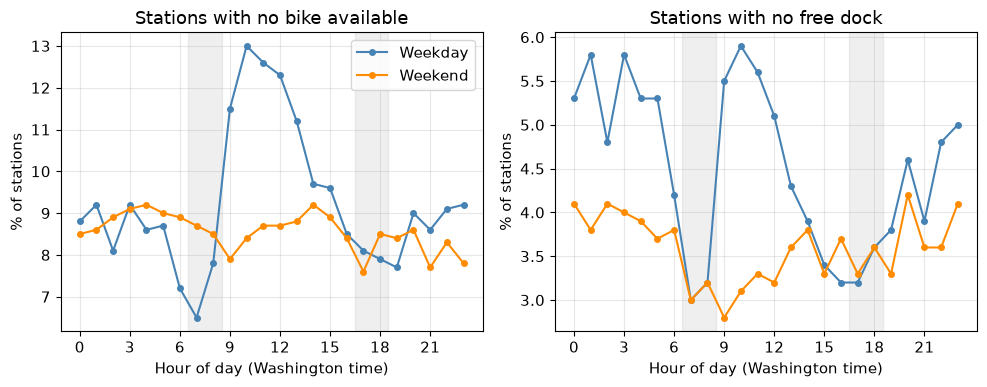

In [ ]:
g = pd.read_csv("gbfs_summary.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for ax, col, title in zip(axes, ["empty", "full"], ["Stations with no bike available", "Stations with no free dock"]):
        for day, colr in [("Weekday", "steelblue"), ("Weekend", "darkorange")]:
            sub = g[g["day_type"] == day]
            ax.plot(sub["hour"], sub[col], marker="o", ms=4, color=colr, label=day)
        for a, b in [(7, 9), (17, 19)]:          # commute peaks: hours 7-8 and 17-18
            ax.axvspan(a - 0.5, b - 0.5, color="gray", alpha=0.12)
        ax.set_title(title); ax.set_xlabel("Hour of day (Washington time)"); ax.set_ylabel("% of stations")
        ax.set_xticks(range(0, 24, 3)); ax.grid(alpha=0.3)
axes[0].legend(); plt.tight_layout(); plt.show()


## 22. Save all results

In [ ]:
with open("results.json", "w") as f:
    json.dump(out, f, indent=1, default=str)
print("Saved results.json")

Saved results.json
